# Does an alphabet-matched source transfer better than ASL?

E1 found that pretraining on **ASL** gives no measurable benefit for Auslan (ΔT(20) ≈ 0, 95% CI
crossing zero for every method). One obvious explanation is that ASL is the wrong source: it is
a **one-handed** alphabet whose handshapes are unrelated to Auslan's, so "A" in ASL and "A" in
Auslan share only a name.

**BSL does not have that problem.** British, Australian and New Zealand Sign Language form the
BANZSL family and share the *same two-handed manual alphabet*. So a BSL source tests transfer
between genuinely matched alphabets, which is what the Task 1 question was really asking.

This notebook adds that arm. It **changes nothing in `src/auslan/`** — the BSL dataset is
described locally and fed to the same `prepare_source`, the same method registry and the same
metrics the main pipeline uses.

## The four arms

| Arm | Source | Target | Tested on | Where it comes from |
|---|---|---|---|---|
| **A** | — | Auslan k=20 from scratch | Roboflow | already in `results.jsonl` (P2) |
| **B** | ASL | Auslan k=20 | Roboflow | already in `results.jsonl` (P3) |
| **C** | **BSL** | Auslan k=20 | Roboflow | **this notebook** |
| **D** | **BSL** | — (no Auslan at all) | Roboflow | **this notebook** |
| **E** | **ASL** | — (no Auslan at all) | Roboflow | **this notebook** |

**Arm C** is the like-for-like replacement of ASL by BSL. **Arm E** is the control that makes
arm D interpretable: D differs from B in *two* ways at once (a different source **and** a
route that skips the drawings), so without E we cannot say which of the two did the work. **Arm D** is the cleaner test the
project has never been able to run: BSL is photographs and Roboflow is photographs, so for the
first time there are no line drawings anywhere in the chain. If D works and A/B/C do not, the
barrier was the medium, not the language.

## Before you start

Same kernel rules as the main notebook: open in VS Code on the `.venv` interpreter, or launch
with `uv run --no-sync jupyter lab`. A plain `uv run` reinstalls the CPU build of torch.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("could not find the repository root (no pyproject.toml above cwd)")


ROOT = find_repo_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import torch

from auslan.config import load_settings
from auslan.methods.torch_base import default_device

settings = load_settings(None)
print(f"repo root       : {ROOT}")
print(f"torch           : {torch.__version__}")
print(f"default_device(): {default_device()}")
if torch.__version__.endswith("+cpu"):
    print("\n!! CPU build of torch — a plain `uv run` replaced it. See the main notebook, cell 1.")

repo root       : D:\Master degree at UTS\Study\2nd sem1\UTS Image Processing and Pattern Recognition\Assignment\Final Project\auslan-image-processing
torch           : 2.14.1+cu130
default_device(): cuda


## 1. Credentials

Only the download needs these. Read from the gitignored notes file, else prompt.

In [2]:
import getpass
import re

KEYS_FILE = ROOT / "notebooks" / "api-keys.local.md"


def keys_from_notes(path: Path) -> dict[str, str]:
    if not path.is_file():
        return {}
    pattern = re.compile(r"`(KAGGLE_API_TOKEN|ROBOFLOW_API_KEY)`\s*\|\s*`([^`]+)`")
    return dict(pattern.findall(path.read_text(encoding="utf-8")))


from_notes = keys_from_notes(KEYS_FILE)
for variable in ("KAGGLE_API_TOKEN",):
    value = from_notes.get(variable) or os.environ.get(variable)
    if not value:
        value = getpass.getpass(f"{variable} (blank to skip): ").strip()
    if value:
        os.environ[variable] = value
        print(f"{variable}: set, {len(value)} characters")
    else:
        print(f"{variable}: skipped — the download will fail without it")

KAGGLE_API_TOKEN: set, 37 characters


## 2. Download the BSL alphabet

`philipilono/bsl-static-alphabet` — about 1 GB, 24 letter classes with roughly 3,000 training
images each. Note the sibling dataset `alifsathar/bsl-fingerspelling-dataset` is a **strict
subset** of this one with training data for A–G only; don't use it.

The archive ships the smaller set again inside `BSL-data/`, so it is internally duplicated.
That is harmless here: `prepare` removes exact and near-duplicates before splitting.

In [3]:
import shutil

BSL_SLUG = "philipilono/bsl-static-alphabet"
BSL_NAME = "bsl_kaggle"
bsl_raw = settings.raw_dir / BSL_NAME

if bsl_raw.is_dir() and any(bsl_raw.iterdir()):
    print(f"{BSL_NAME} already downloaded at {bsl_raw}")
else:
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    partial = bsl_raw.with_name(f"{BSL_NAME}.downloading")
    shutil.rmtree(partial, ignore_errors=True)
    print("downloading, about 1 GB ...")
    api.dataset_download_files(BSL_SLUG, path=str(partial), unzip=True, quiet=False)
    partial.rename(bsl_raw)
    print(f"done -> {bsl_raw}")

bsl_kaggle already downloaded at data\raw\bsl_kaggle


## 3. Prepare it

The BSL set is described here rather than in `registry.py`, so `src/auslan/` is untouched.
`fallback="skin"` matches the other photographic sets; `split=True` carves 70/15/15.

**The label space is the interesting part.** This dataset omits **H and J**, not J and Z. Two
independently built BSL datasets both do this, which says the moving letters of the two-handed
BANZSL alphabet are not the ones ASL corpora drop. Our Auslan space omits J and Z, inherited
from ASL convention — so the two alphabets overlap on **23** letters, not 24.

Expect roughly 10–15 minutes: about 67,000 unique images through MediaPipe.

In [4]:
from functools import partial as bind

from auslan.data.classes import LETTERS, LabelSpace
from auslan.data.prepare import load_prepared, prepare_source
from auslan.data.registry import DatasetSpec
from auslan.preprocessing.factory import build_cropper

BSL_LETTERS = tuple(c for c in LETTERS if c not in set("HJ"))  # this dataset's own 24
SHARED_LETTERS = tuple(c for c in LETTERS if c not in set("HJZ"))  # BSL ∩ Auslan = 23
SHARED_SPACE = LabelSpace(SHARED_LETTERS)

print(f"BSL letters     ({len(BSL_LETTERS)}): {''.join(BSL_LETTERS)}")
print(f"shared with Auslan ({len(SHARED_LETTERS)}): {''.join(SHARED_LETTERS)}\n")

bsl_spec = DatasetSpec(BSL_NAME, bsl_raw, BSL_LETTERS, "skin", split=True)
bsl_work = prepare_source(
    bsl_spec,
    settings.work_dir,
    bind(build_cropper, settings.models_dir, bsl_spec.fallback, settings.crop_size),
    seed=settings.split_seed,
    max_hamming=settings.near_duplicate_hamming,
    workers=settings.workers,
    cropper_key=f"{bsl_spec.fallback}-{settings.crop_size}",
)
print(f"prepared -> {bsl_work}")

BSL letters     (24): ABCDEFGIKLMNOPQRSTUVWXYZ
shared with Auslan (23): ABCDEFGIKLMNOPQRSTUVWXY

prepared -> data\work\bsl_kaggle


## 4. Check it looks like photographs

The whole premise is that BSL is photographic where the Kaggle Auslan set is line drawings.
Confirm that before training anything: if the detection rate here were near zero, this arm
would be measuring the same media problem all over again.

22,556 images kept after de-duplication, 24 letters
splits: {'train': 15789, 'test': 3384, 'val': 3383}



,images,detected %,two hands %
bsl_kaggle,"22,556",80.2,24.6
auslan_kaggle,"11,028",0.0,0.0
auslan_roboflow,250,100.0,94.4
asl_alphabet,"16,980",78.5,0.7


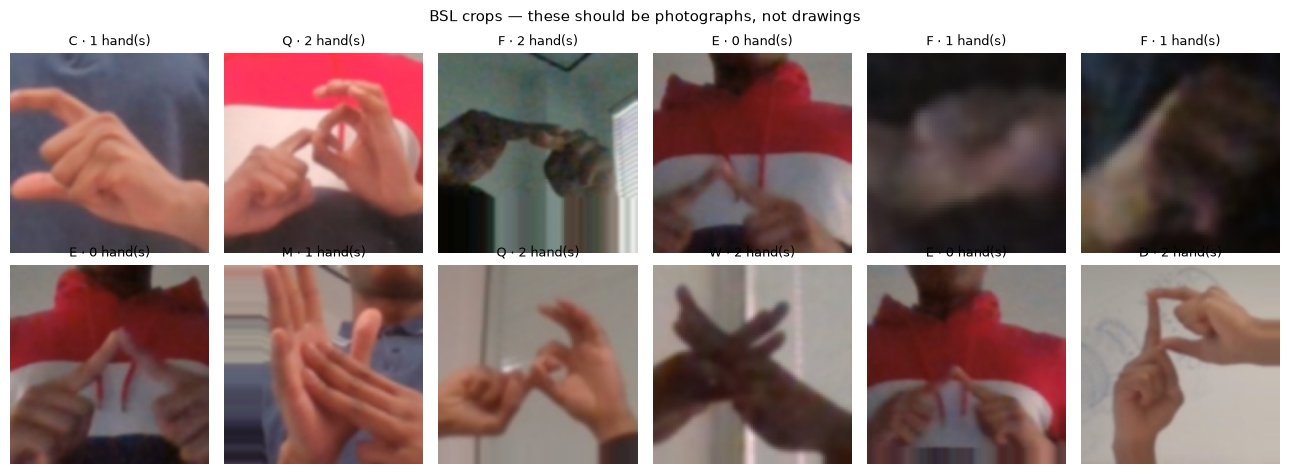

In [5]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd

bsl_catalog, bsl_landmarks = load_prepared(bsl_work)
print(f"{len(bsl_catalog):,} images kept after de-duplication, {bsl_catalog['label'].nunique()} letters")
print(f"splits: {bsl_catalog['split'].value_counts().to_dict()}\n")

rates = {}
for name in ("bsl_kaggle", "auslan_kaggle", "auslan_roboflow", "asl_alphabet"):
    folder = settings.work_dir / name
    if (folder / "catalog.csv").exists():
        frame = pd.read_csv(folder / "catalog.csv")
        rates[name] = {
            "images": len(frame),
            "detected %": (frame["n_hands"] > 0).mean() * 100,
            "two hands %": (frame["n_hands"] == 2).mean() * 100,
        }
display(pd.DataFrame(rates).T.style.format({"images": "{:,.0f}", "detected %": "{:.1f}", "two hands %": "{:.1f}"}))

sample = bsl_catalog.sample(min(12, len(bsl_catalog)), random_state=0)
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    try:
        ax.imshow(mpimg.imread(row["crop_path"]))
    except (FileNotFoundError, OSError):
        ax.text(0.5, 0.5, "missing", ha="center", va="center", fontsize=8)
    ax.set_title(f"{row['label']} · {row['n_hands']} hand(s)", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("BSL crops — these should be photographs, not drawings", fontsize=11)
fig.tight_layout()
plt.show()

## 5. Build the sample sets

All three datasets are read through the same `SampleSet` the main pipeline uses, so the crops,
landmarks and style transform behave identically. BSL is read in the **23-letter shared space**
so arm D can be scored against Roboflow directly; Auslan keeps its own 24-letter space, which
is fine for arm C because transfer replaces the output layer anyway.

In [6]:
from auslan.data.classes import AUSLAN_SPACE
from auslan.data.sample_set import SampleSet
from auslan.data.splits import sample_k_shot

HEADLINE_K = 20


def sample_set(name, space, split=None, styled=False):
    """A SampleSet over a prepared dataset, filtered to the letters the space defines."""
    frame, landmarks = load_prepared(settings.work_dir / name)
    frame = frame[frame["label"].isin(space.letters)]
    if split is not None:
        frame = frame[frame["split"] == split]
    return SampleSet(frame, landmarks, space, settings.image_size, styled=styled)


bsl_train = sample_set(BSL_NAME, SHARED_SPACE, split="train")
bsl_val = sample_set(BSL_NAME, SHARED_SPACE, split="val")
# Arm E needs ASL in the same 23-letter space as BSL, so D and E differ only in source.
asl_train = sample_set("asl_alphabet", SHARED_SPACE, split="train")
asl_val = sample_set("asl_alphabet", SHARED_SPACE, split="val")
# Arm D trains on BSL PHOTOGRAPHS, so it must be tested on photographs. The transform T
# binarises colour into drawing-like images to match the Kaggle Auslan set; applying it
# here would put drawings back into the one chain meant to have none.
roboflow_shared = sample_set("auslan_roboflow", SHARED_SPACE, styled=False)
roboflow_shared_styled = sample_set("auslan_roboflow", SHARED_SPACE, styled=True)
roboflow_auslan = sample_set("auslan_roboflow", AUSLAN_SPACE, styled=True)

print(f"BSL train / val          : {len(bsl_train):,} / {len(bsl_val):,}  ({len(SHARED_SPACE)} classes)")
print(f"ASL train / val          : {len(asl_train):,} / {len(asl_val):,}  ({len(SHARED_SPACE)} classes)")
print(f"Roboflow, shared space   : {len(roboflow_shared):,}  ({len(SHARED_SPACE)} cls, photos)")
print(f"Roboflow, Auslan space   : {len(roboflow_auslan):,}  ({len(AUSLAN_SPACE)} classes)")

BSL train / val          : 15,220 / 3,261  (23 classes)
ASL train / val          : 11,383 / 2,439  (23 classes)
Roboflow, shared space   : 242  (23 cls, photos)
Roboflow, Auslan space   : 250  (24 classes)


## 6. Run arms C and D

For each method and seed the BSL model is trained **once** and used for both arms, so the extra
cost over arm D alone is only the short Auslan fine-tune. Trained BSL models are cached to
`artifacts/bsl_pretrained/`, so re-running this cell after a restart is cheap.

Start with one seed to check it works. Switch to `(0, 1, 2)` for the figure you report, so it
is comparable with the three-seed P2/P3 numbers already in the store.

In [7]:
import time

import joblib

from auslan.evaluation.metrics import accuracy, macro_f1, top_k_accuracy
from auslan.methods import create

METHODS = ("m4_resnet18", "m3_cnn")
SEEDS = (0, 1, 2)  # three draws: run-to-run noise on CUDA is ~1.7 points, so one is not enough
CACHE = settings.artifacts_dir / "bsl_pretrained"
CACHE.mkdir(parents=True, exist_ok=True)


def score(model, samples, n_classes):
    proba = model.predict_proba(samples)
    predicted = proba.argmax(axis=1)
    return {
        "macro_f1": macro_f1(samples.labels, predicted, n_classes) * 100,
        "accuracy": accuracy(samples.labels, predicted) * 100,
        "top3": top_k_accuracy(proba, samples.labels, 3) * 100,
    }


rows = []
for method in METHODS:
    for seed in SEEDS:
        cached = CACHE / f"{method}-s{seed}.joblib"
        if cached.exists():
            bsl_model = joblib.load(cached)
            print(f"{method} s{seed}: loaded cached BSL model")
        else:
            print(f"{method} s{seed}: training on BSL ({len(bsl_train):,} images) ...")
            started = time.perf_counter()
            bsl_model = create(method, seed=seed).fit(bsl_train, val=bsl_val)
            joblib.dump(bsl_model, cached)
            print(f"   done in {(time.perf_counter() - started) / 60:.1f} min")

        # Arm D — BSL straight to Roboflow, no Auslan anywhere in the chain
        rows.append({"arm": "D  BSL -> Roboflow", "method": method, "seed": seed,
                     **score(bsl_model, roboflow_shared, len(SHARED_SPACE))})
        rows.append({"arm": "D* BSL -> Roboflow (styled, diagnostic)", "method": method,
                     "seed": seed,
                     **score(bsl_model, roboflow_shared_styled, len(SHARED_SPACE))})


        # Arm E — the control: same route as D, same label space, but an ASL source. Cached under a
        # separate name so it never collides with the BSL models.
        asl_cached = CACHE / f"asl_shared-{method}-s{seed}.joblib"
        if asl_cached.exists():
            asl_model = joblib.load(asl_cached)
            print(f"{method} s{seed}: loaded cached ASL model")
        else:
            print(f"{method} s{seed}: training on ASL ({len(asl_train):,} images) ...")
            started = time.perf_counter()
            asl_model = create(method, seed=seed).fit(asl_train, val=asl_val)
            joblib.dump(asl_model, asl_cached)
            print(f"   done in {(time.perf_counter() - started) / 60:.1f} min")
        rows.append({"arm": "E  ASL -> Roboflow", "method": method, "seed": seed,
                     **score(asl_model, roboflow_shared, len(SHARED_SPACE))})

        # Arm C — BSL as the starting point for the Auslan few-shot fine-tune
        kaggle_frame, kaggle_landmarks = load_prepared(settings.work_dir / "auslan_kaggle")
        train_rows = sample_k_shot(kaggle_frame[kaggle_frame["split"] == "train"], HEADLINE_K, seed)
        auslan_train = SampleSet(train_rows, kaggle_landmarks, AUSLAN_SPACE, settings.image_size)
        # runner.py draws only settings.val_per_class images per letter for P2/P3, so the
        # tuning data stays "comparable to k". Arm C must match it or the comparison with
        # arms A and B is unfair: the whole split is about seven times larger.
        val_rows = sample_k_shot(
            kaggle_frame[kaggle_frame["split"] == "val"], settings.val_per_class, seed
        )
        auslan_val = SampleSet(val_rows, kaggle_landmarks, AUSLAN_SPACE, settings.image_size)
        print(f"{method} s{seed}: fine-tuning on {len(auslan_train)} images, tuning on {len(auslan_val)} ...")
        tuned = create(method, seed=seed).fit(auslan_train, val=auslan_val, init=bsl_model)
        rows.append({"arm": "C  BSL -> Auslan -> Roboflow", "method": method, "seed": seed,
                     **score(tuned, roboflow_auslan, len(AUSLAN_SPACE))})

new_results = pd.DataFrame(rows)
display(new_results.round(2))

m4_resnet18 s0: loaded cached BSL model
m4_resnet18 s0: loaded cached ASL model
m4_resnet18 s0: fine-tuning on 480 images, tuning on 240 ...
m4_resnet18 s1: loaded cached BSL model
m4_resnet18 s1: loaded cached ASL model
m4_resnet18 s1: fine-tuning on 480 images, tuning on 240 ...
m4_resnet18 s2: loaded cached BSL model
m4_resnet18 s2: loaded cached ASL model
m4_resnet18 s2: fine-tuning on 480 images, tuning on 240 ...
m3_cnn s0: loaded cached BSL model
m3_cnn s0: loaded cached ASL model
m3_cnn s0: fine-tuning on 480 images, tuning on 240 ...
m3_cnn s1: loaded cached BSL model
m3_cnn s1: loaded cached ASL model
m3_cnn s1: fine-tuning on 480 images, tuning on 240 ...
m3_cnn s2: loaded cached BSL model
m3_cnn s2: loaded cached ASL model
m3_cnn s2: fine-tuning on 480 images, tuning on 240 ...


,arm,method,seed,macro_f1,accuracy,top3
0,D BSL -> Roboflow,m4_resnet18,0,23.27,22.31,38.43
1,"D* BSL -> Roboflow (styled, diagnostic)",m4_resnet18,0,1.12,3.31,12.81
2,E ASL -> Roboflow,m4_resnet18,0,2.92,4.96,13.64
3,C BSL -> Auslan -> Roboflow,m4_resnet18,0,12.61,15.20,33.60
4,D BSL -> Roboflow,m4_resnet18,1,22.37,22.31,41.32
5,"D* BSL -> Roboflow (styled, diagnostic)",m4_resnet18,1,1.11,4.55,13.64
6,E ASL -> Roboflow,m4_resnet18,1,5.03,7.02,15.70
7,C BSL -> Auslan -> Roboflow,m4_resnet18,1,14.32,16.80,31.20
8,D BSL -> Roboflow,m4_resnet18,2,26.07,25.62,42.56
9,"D* BSL -> Roboflow (styled, diagnostic)",m4_resnet18,2,0.77,3.72,12.81


## 7. Compare against the ASL arms

Arms A and B come straight out of the existing store, so nothing is re-run. Chance is
100/24 ≈ 4.2% for the Auslan space and 100/23 ≈ 4.3% for the shared space — the number to beat
before any of this means anything.

Macro-F1 % on Roboflow   (chance ≈ 4.2)



method,m3_cnn,m4_resnet18
arm,,
A Auslan from scratch,0.83,8.44
B ASL -> Auslan -> Roboflow,1.43,10.48
C BSL -> Auslan -> Roboflow,1.69,14.27
D BSL -> Roboflow,3.49,23.91
"D* BSL -> Roboflow (styled, diagnostic)",0.68,1.00
E ASL -> Roboflow,1.93,3.93


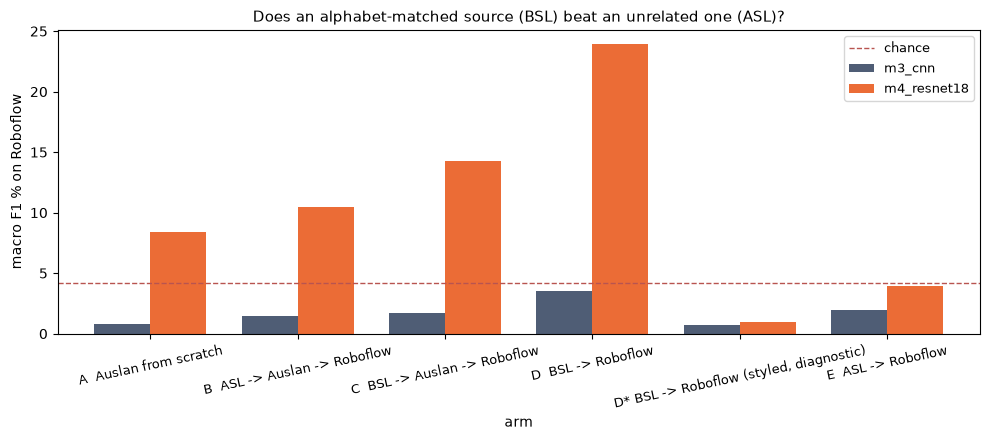

In [8]:
from auslan.results import ResultStore

store_table = ResultStore(settings.artifacts_dir).table()
existing = store_table[
    (store_table["test_set"] == "roboflow")
    & (store_table["k"] == HEADLINE_K)
    & (store_table["tag"] == "")
    & (store_table["method"].isin(METHODS))
]
old = (
    existing.assign(arm=existing["protocol"].map({"P2": "A  Auslan from scratch", "P3": "B  ASL -> Auslan -> Roboflow"}))
    .groupby(["arm", "method"])[["macro_f1", "accuracy", "top3"]]
    .mean()
    .mul(100)
    .reset_index()
)
combined = pd.concat([old, new_results.groupby(["arm", "method"])[["macro_f1", "accuracy", "top3"]].mean().reset_index()])
pivot = combined.pivot_table(index="arm", columns="method", values="macro_f1").sort_index()
print(f"Macro-F1 % on Roboflow   (chance ≈ 4.2)\n")
display(pivot.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
pivot.plot.bar(ax=ax, width=0.76, color=["#4f5d75", "#eb6c36"])
ax.axhline(100 / 24, color="#b85450", linestyle="--", linewidth=1, label="chance")
ax.set_ylabel("macro F1 % on Roboflow")
ax.set_title("Does an alphabet-matched source (BSL) beat an unrelated one (ASL)?", fontsize=11)
ax.tick_params(axis="x", rotation=12, labelsize=9)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### How to read it

Arms D and E share a route, a label space and a test set, so **D − E is the effect of the
source language alone**. Arms B and D differ in both source and route, so that gap is the
two changes combined.

|  | via Kaggle Auslan | straight to Roboflow |
|---|---|---|
| **ASL** source | arm B | **arm E** |
| **BSL** source | arm C | arm D |

- **E well below D** — the matched alphabet is doing real work, and BSL is genuinely the
  better source.
- **E close to D** — the source barely matters; nearly all of D's advantage came from
  dropping the line drawings, and the BANZSL argument is weaker than it looks.
- **E above B** — skipping the drawings helps even a mismatched source, which is the
  strongest possible statement that the Kaggle Auslan set is the problem.


## 8. Save to `results/tong/bsl/`

In [9]:
destination = ROOT / "results" / "tong" / "bsl"
destination.mkdir(parents=True, exist_ok=True)
new_results.to_csv(destination / "bsl_arms.csv", index=False)
pivot.round(3).to_csv(destination / "comparison_macro_f1.csv")
fig.savefig(destination / "comparison.png", dpi=200, bbox_inches="tight")  # for the report

(destination / "README.md").write_text(
    "# Tong — BSL source comparison\n\n"
    "Does an alphabet-matched source transfer better than ASL?\n\n"
    f"Run from `notebooks/bsl_comparison.ipynb` on {torch.cuda.get_device_name(0)}"
    f" ({torch.__version__}), methods {list(METHODS)}, seeds {list(SEEDS)}.\n\n"
    f"Source: Kaggle `{BSL_SLUG}` — {len(bsl_catalog):,} images after de-duplication, "
    f"{len(BSL_LETTERS)} letters (this dataset omits H and J, not J and Z).\n"
    f"BSL and our Auslan label space share {len(SHARED_LETTERS)} letters.\n\n"
    "Arms A and B are the existing P2/P3 Roboflow results; C, D and E are new.\n"
    "Chance is about 4.2%.\n\n"
    "**Licence: Unknown (none declared).** Source, licence and what we actually used: "
    "[bsl.md](bsl.md).\n",
    encoding="utf-8",
)
print(f"written to {destination}")
for path in sorted(destination.iterdir()):
    print(f"  {path.name}")

written to D:\Master degree at UTS\Study\2nd sem1\UTS Image Processing and Pattern Recognition\Assignment\Final Project\auslan-image-processing\results\tong\bsl
  bsl.md
  bsl_arms.csv
  comparison.png
  comparison_macro_f1.csv
  experiment_brief.md
  README.md
